# Cell Profiling Anywhere

## From microscopy images to cell profiles

**Correct illumination → segment cells → measure features → save results.**

This notebook demonstrates **illumination correction, segmentation, and measurements** with `cp-anywhere`.
The main workflow uses corrected images to find cells and calculate their features.
We add a clearly labeled simulated lighting gradient to the real images so correction has a known, visible target.
You can use image files or NumPy arrays, work with pandas tables, and save results for later analysis.
The measurement engine runs in Rust. No CellProfiler application is needed for this example.

We use a bundled real DNA/actin image from [BBBC007](https://bbbc.broadinstitute.org/BBBC007).
No image download is needed. The sample is a small crop, not a complete biological experiment.

### Start here

From the repository root, run `uv sync --frozen --group docs`.
Open this notebook and select the repository's `.venv` Python interpreter.
Run the cells in order.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cp_anywhere as cp

# Work from either the repository root or this notebook's folder.
project = Path.cwd()
if not (project / "fixtures").exists():
    project = Path("../..")

sample = project / "fixtures/real/real_bbbc007"

## 1. Load two images

`load_array` reads NPY, TIFF, PNG, and other supported image formats.
These sample images are 8-bit, so dividing by `255` puts intensities between zero and one.
For your own data, change the file paths and use the correct intensity scale.

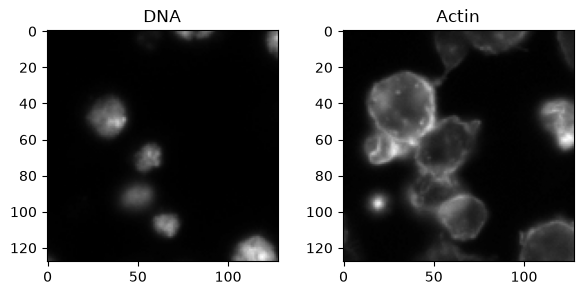

In [2]:
dna = cp.load_array(sample / "DNA.npy").astype(float) / 255
actin = cp.load_array(sample / "Actin.npy").astype(float) / 255

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(dna, cmap="gray")
axes[0].set_title("DNA")
axes[1].imshow(actin, cmap="gray")
axes[1].set_title("Actin")
plt.show()

## 2. Correct illumination

**Controlled demonstration: real cells, simulated uneven lighting.**
A small crop alone does not tell us its true microscope illumination.
Instead, add a known lighting gradient: 25% brightness at the left edge and 100% at the right.
The unmodified images are the reference for this added distortion, not proof that the original lighting was uniform.

Our simulated flat-field reference contains only this gradient, without cells.
`calculate_illumination` fits a smooth function to that reference.
`apply_illumination` divides the shaded images by that function.
We use the same simulated lighting for both channels in this example.
`rescale_option="No"` keeps the original intensity scale.

The corrected images feed segmentation and measurements below.
For real experiments, use measured calibration images or suitable representative images for each channel.

In [3]:
# Simulate less light on the left side of the field.
flat_field = np.tile(np.linspace(0.25, 1.0, dna.shape[1]), (dna.shape[0], 1))
dna_shaded = dna * flat_field
actin_shaded = actin * flat_field

# Estimate the correction from the flat-field reference, not from the cells.
illumination = cp.calculate_illumination(
    flat_field, smoothing_method="Fit Polynomial", rescale_option="No"
)
dna_corrected = cp.apply_illumination(dna_shaded, illumination)
actin_corrected = cp.apply_illumination(actin_shaded, illumination)

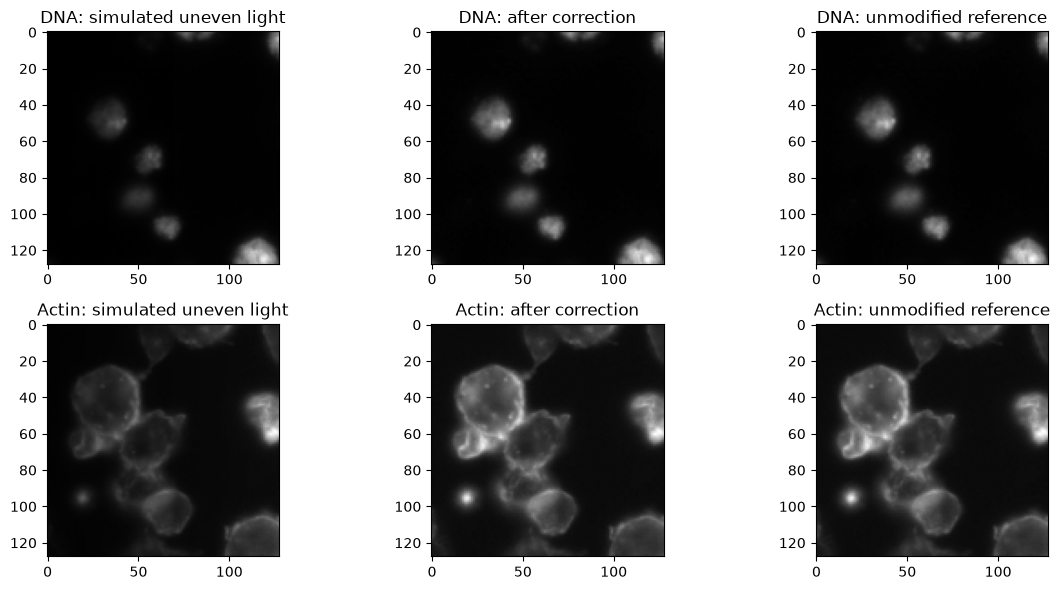

In [4]:
# All three images in each row use the reference image's display range.
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes[0, 0].imshow(dna_shaded, cmap="gray", vmin=0, vmax=dna.max())
axes[0, 0].set_title("DNA: simulated uneven light")
axes[0, 1].imshow(dna_corrected, cmap="gray", vmin=0, vmax=dna.max())
axes[0, 1].set_title("DNA: after correction")
axes[0, 2].imshow(dna, cmap="gray", vmin=0, vmax=dna.max())
axes[0, 2].set_title("DNA: unmodified reference")
axes[1, 0].imshow(actin_shaded, cmap="gray", vmin=0, vmax=actin.max())
axes[1, 0].set_title("Actin: simulated uneven light")
axes[1, 1].imshow(actin_corrected, cmap="gray", vmin=0, vmax=actin.max())
axes[1, 1].set_title("Actin: after correction")
axes[1, 2].imshow(actin, cmap="gray", vmin=0, vmax=actin.max())
axes[1, 2].set_title("Actin: unmodified reference")
plt.tight_layout()
plt.show()

### Did the correction work?

Compare mean absolute pixel error against the unmodified reference. Smaller is better.
This measures recovery from the simulated lighting, not the accuracy of a real instrument calibration.

In [5]:
errors = pd.DataFrame(
    {
        "Before correction": [
            np.abs(dna_shaded - dna).mean(),
            np.abs(actin_shaded - actin).mean(),
        ],
        "After correction": [
            np.abs(dna_corrected - dna).mean(),
            np.abs(actin_corrected - actin).mean(),
        ],
    },
    index=["DNA", "Actin"],
)
errors

,Before correction,After correction
DNA,0.010761,1.234982e-09
Actin,0.038748,3.652901e-09


## 3. Segment nuclei, cells, and cytoplasm

Find nuclei in the corrected DNA image. Grow cell regions around them using the corrected actin image.
Then remove the nuclei from those regions to get cytoplasm.

The nucleus size limits are in pixels. They suit this example, not every dataset.
These are new segmentations, not the dataset's manual ground truth.

Check the colored labels and outlines before measuring. Green lines show where each object ends on the corrected image.

In [6]:
nuclei = cp.identify_primary_objects(
    dna_corrected,
    min_diameter=10,
    max_diameter=40,
    exclude_size=True,
)
cells = cp.identify_secondary_objects(actin_corrected, nuclei.labels)
cytoplasm = cp.identify_tertiary_objects(
    nuclei.labels,
    cells.labels,
    shrink_primary=False,
)

print(f"Found {nuclei.object_count} nuclei")

Found 5 nuclei


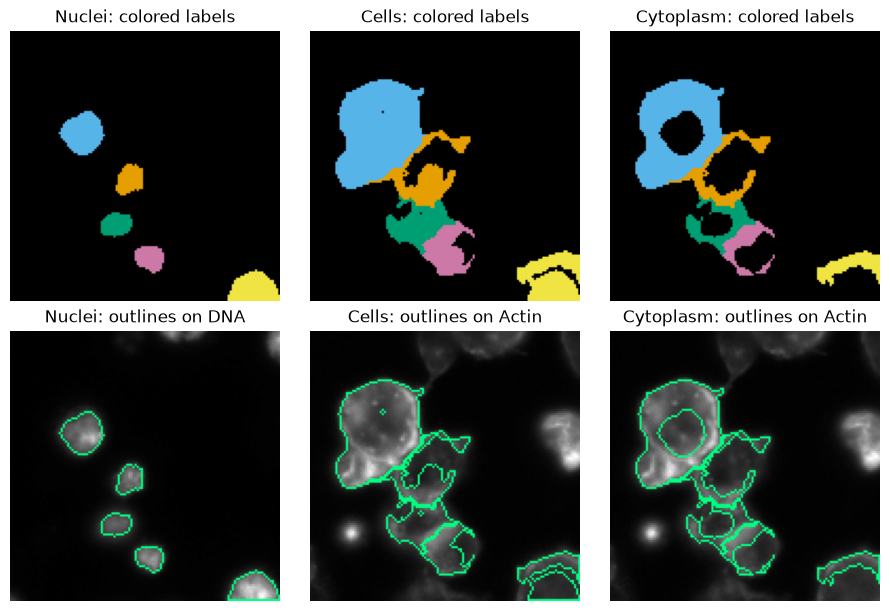

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6), layout="constrained")
for column, (name, labels, image, channel) in enumerate(
    [
        ("Nuclei", nuclei.labels, dna_corrected, "DNA"),
        ("Cells", cells.labels, actin_corrected, "Actin"),
        ("Cytoplasm", cytoplasm.labels, actin_corrected, "Actin"),
    ]
):
    axes[0, column].imshow(cp.preview_segmentation(labels, mode="labels"))
    axes[0, column].set_title(f"{name}: colored labels")
    axes[1, column].imshow(cp.preview_segmentation(labels, image))
    axes[1, column].set_title(f"{name}: outlines on {channel}")
    axes[0, column].set_axis_off()
    axes[1, column].set_axis_off()
plt.show()

## 4. Measure cell features

Give `measure` the corrected images and the labels from segmentation.
The names become part of the output, so your channels and compartments stay identifiable.

This call measures intensity, size/shape, and neighboring cells.
All three compartments share cell IDs because we created them together.
The areas use pixel units.

In [8]:
images = {"DNA": dna_corrected, "Actin": actin_corrected}
objects = {
    "Cells": cells.labels,
    "Nuclei": nuclei.labels,
    "Cytoplasm": cytoplasm.labels,
}

result = cp.measure(
    images,
    objects,
    families=["image_intensity", "object_intensity", "object_size_shape", "neighbors"],
)

Make a pandas table with one row per cell.
The full table contains all cell features. Here we show a few useful columns.

In [9]:
profiles = pd.DataFrame(result.features["Cells"], index=result.object_ids["Cells"])
profiles.index.name = "cell_id"

print(f"{len(profiles)} cells, {len(profiles.columns)} features per cell")
profiles[
    [
        "AreaShape_Area",
        "Intensity_MeanIntensity_DNA",
        "Intensity_MeanIntensity_Actin",
        "Neighbors_NumberOfNeighbors_Adjacent",
    ]
].round(3)

5 cells, 104 features per cell


,AreaShape_Area,Intensity_MeanIntensity_DNA,Intensity_MeanIntensity_Actin,Neighbors_NumberOfNeighbors_Adjacent
cell_id,,,,
1,1601.0,0.070,0.273,1
2,509.0,0.088,0.199,2
3,438.0,0.107,0.196,2
4,368.0,0.129,0.220,1
5,505.0,0.210,0.163,0


Now use ordinary pandas plotting. Each point is one cell.

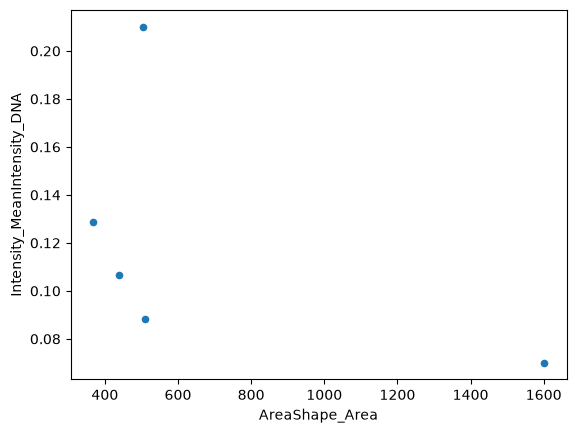

In [10]:
profiles.plot.scatter(x="AreaShape_Area", y="Intensity_MeanIntensity_DNA")
plt.show()

## 5. Save the results

Save the cell table as CSV or Parquet. Save the labels and correction function as NPY.
Save the corrected images as TIFF and the cell outline preview as PNG.
You can also save all compartments together, or export to SQLite.

These example files go into `docs/_build/notebook-output`.
Change `output` to a directory of your choice. Rerunning these cells replaces the example files.

In [11]:
output = project / "docs/_build/notebook-output"
output.mkdir(parents=True, exist_ok=True)

profiles.to_csv(output / "cell_profiles.csv")
profiles.to_parquet(output / "cell_profiles.parquet")
cp.save_array(cells.labels, output / "cells.npy")
cell_overlay = cp.preview_segmentation(cells.labels, actin_corrected)
cp.save_array(cell_overlay, output / "cell_outlines.png", bit_depth="No conversion")
cp.save_array(flat_field, output / "flat_field_reference.npy")
cp.save_array(illumination, output / "illumination.npy")
cp.save_array(
    dna_corrected, output / "dna_corrected.tiff", bit_depth="32-bit floating point"
)
cp.save_array(
    actin_corrected, output / "actin_corrected.tiff", bit_depth="32-bit floating point"
)

# Keep all compartments in one table, with one row per cell.
result.to_parquet(output / "all_compartments.parquet", mode="joined")
result.to_sqlite(output / "profiles.sqlite", if_exists="replace")

print(f"Saved files to {output}")

Saved files to ../../docs/_build/notebook-output


Read the table back whenever you need it.

In [12]:
saved_profiles = pd.read_parquet(output / "cell_profiles.parquet")
saved_profiles.head()

,AreaShape_Area,AreaShape_BoundingBoxArea,AreaShape_BoundingBoxMaximum_X,AreaShape_BoundingBoxMaximum_Y,AreaShape_BoundingBoxMinimum_X,AreaShape_BoundingBoxMinimum_Y,AreaShape_Center_X,AreaShape_Center_Y,AreaShape_Compactness,AreaShape_ConvexArea,...,Location_MaxIntensity_Y_DNA,Location_MaxIntensity_Z_Actin,Location_MaxIntensity_Z_DNA,Neighbors_AngleBetweenNeighbors_Adjacent,Neighbors_FirstClosestDistance_Adjacent,Neighbors_FirstClosestObjectNumber_Adjacent,Neighbors_NumberOfNeighbors_Adjacent,Neighbors_PercentTouching_Adjacent,Neighbors_SecondClosestDistance_Adjacent,Neighbors_SecondClosestObjectNumber_Adjacent
cell_id,,,,,,,,,,,,,,,,,,,,,
1,1601.0,2236.0,55.0,75.0,12.0,23.0,31.665209,47.071205,1.501705,1770.0,...,51.0,0.0,0.0,24.671783,30.845242,2,1,25.120773,47.879350,3
2,509.0,1813.0,76.0,84.0,27.0,47.0,54.703340,67.581532,6.844658,1031.0,...,68.0,0.0,0.0,122.359160,23.659939,3,2,32.031250,30.845242,1
3,438.0,924.0,69.0,106.0,36.0,78.0,50.872146,90.929224,2.924945,636.0,...,91.0,0.0,0.0,123.457987,18.673789,4,2,41.772152,23.659939,2
4,368.0,650.0,78.0,116.0,53.0,90.0,64.578804,103.611413,2.373903,496.0,...,108.0,0.0,0.0,31.895405,18.673789,3,1,28.346457,37.358762,2
5,505.0,720.0,128.0,128.0,98.0,104.0,114.211881,116.659406,3.864603,609.0,...,125.0,0.0,0.0,7.379061,51.319513,4,0,0.000000,68.366398,3


## A few optional extras

The same arrays work with more of the Python API.
These independent examples do not change the profiles saved above.

### Add texture measurements

Measure actin texture within the same cells. The result has one row per cell.

In [13]:
texture = cp.measure_texture(actin_corrected, cells.labels, image_name="Actin")
texture_profiles = pd.DataFrame(texture.objects, index=profiles.index)
texture_profiles.head()

,Texture_AngularSecondMoment_Actin_3_00_256,Texture_AngularSecondMoment_Actin_3_01_256,Texture_AngularSecondMoment_Actin_3_02_256,Texture_AngularSecondMoment_Actin_3_03_256,Texture_Contrast_Actin_3_00_256,Texture_Contrast_Actin_3_01_256,Texture_Contrast_Actin_3_02_256,Texture_Contrast_Actin_3_03_256,Texture_Correlation_Actin_3_00_256,Texture_Correlation_Actin_3_01_256,...,Texture_SumEntropy_Actin_3_02_256,Texture_SumEntropy_Actin_3_03_256,Texture_SumVariance_Actin_3_00_256,Texture_SumVariance_Actin_3_01_256,Texture_SumVariance_Actin_3_02_256,Texture_SumVariance_Actin_3_03_256,Texture_Variance_Actin_3_00_256,Texture_Variance_Actin_3_01_256,Texture_Variance_Actin_3_02_256,Texture_Variance_Actin_3_03_256
cell_id,,,,,,,,,,,,,,,,,,,,,
1,0.000668,0.000664,0.000736,0.000649,439.307212,536.130917,317.030199,461.980268,0.605328,0.500375,...,7.202684,7.170636,1786.881343,1610.002126,1875.455745,1760.330580,556.547139,536.533261,548.121486,555.577712
2,0.002032,0.002407,0.002300,0.002249,120.460843,243.901141,185.329032,168.348534,0.752329,0.519222,...,6.482114,6.508872,852.288313,770.709277,846.016400,801.797367,243.187289,253.652604,257.836358,242.536475
3,0.002363,0.002122,0.002305,0.002340,181.111111,390.394040,254.645963,223.557432,0.584886,0.057455,...,6.306840,6.264215,691.474411,437.988696,577.218124,730.934886,218.146381,207.095684,207.966022,238.623080
4,0.002477,0.002595,0.002638,0.003069,140.702128,313.657371,129.455224,102.114173,0.751156,0.415451,...,6.429325,6.333099,990.143604,759.502929,1006.184562,1061.272816,282.711433,268.290075,283.909947,290.846747
5,0.006010,0.007232,0.006347,0.006566,58.195545,71.420420,85.896648,86.452096,0.750438,0.615900,...,5.529878,5.347700,408.185343,300.464158,363.063583,355.387509,116.595222,92.971145,112.240058,110.459901


### Already have images and labels on disk?

`measure_files` skips the segmentation steps and returns a pandas table directly.
Here we use the bundled manual-derived labels, so these measurements differ from our new segmentation.
This example keeps the original 8-bit intensity scale.

In [14]:
file_measurements = cp.measure_files(sample / "DNA.npy", sample / "labels.npy")
file_measurements.head()

,image_id,scope,object_id,feature,value
0,Image,Cells,1,Intensity_IntegratedIntensityEdge_DNA,366.0
1,Image,Cells,2,Intensity_IntegratedIntensityEdge_DNA,482.0
2,Image,Cells,3,Intensity_IntegratedIntensityEdge_DNA,1207.0
3,Image,Cells,4,Intensity_IntegratedIntensityEdge_DNA,737.0
4,Image,Cells,1,Intensity_IntegratedIntensity_DNA,27788.0


## Take it anywhere

Replace the sample files with your own aligned images.
Use existing labels or create them in Python.
Measure, inspect, and export without leaving your analysis environment.

The bundled sample is a 128 × 128 crop of BBBC007v1 Drosophila Kc167 cells, field `A9 p10`, with a CC0 waiver.
Its provenance is recorded in `reference/vendor/bbbc007/README.md`.

This notebook covers supported native Python features, not every CellProfiler module or the browser API.
Inspect segmentation before interpreting measurements.
The docs build runs every code cell, so the example stays executable.